# 1. 🎬 Your first AR edit

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/1-images-and-coordinates.ipynb)

## One idea: make an AR edit, then bring it home 🪄

Landpy helps you build small augmented-reality effects in Python. Select a region of an image, work on that region, and put the result back in the right place. For example, find a face, color its lips, or place a transparent overlay on a tilted surface.

The useful bit is **`retrace()`**: record a crop with `save_trace=True`, edit the crop, then retrace it. The edited pixels return to the original canvas while the surrounding image stays in place. You do not have to manually calculate the paste coordinates. A checkpoint and `undo()` serve a different purpose: restoring the exact earlier state.

### A glimpse of where we are going

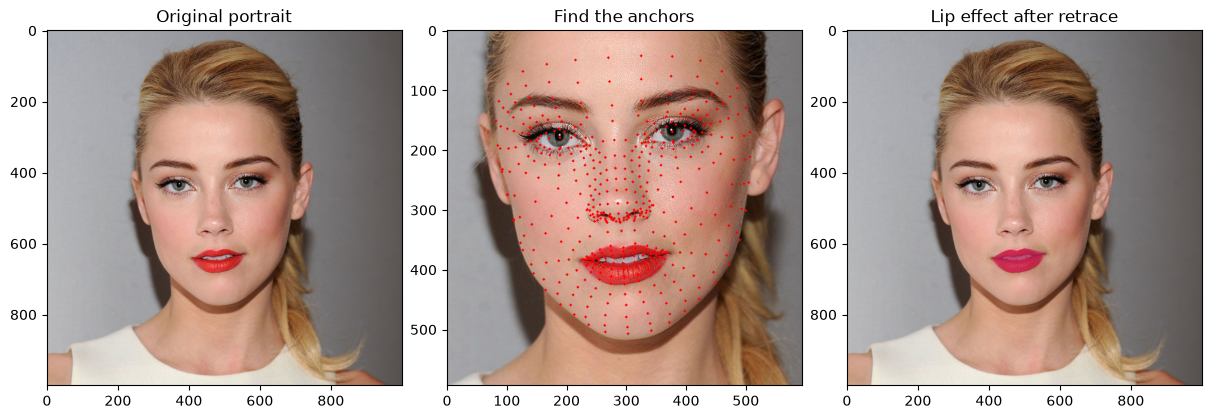

This is a saved result from **[notebook 8](https://github.com/bateni1380/landpy/blob/master/tutorials/8_face_models_and_effects.ipynb)**, not a generated demonstration. You can enjoy the preview now without downloading a model. Notebook 8 walks through every stage, including the mask and debugger snapshots. The sample portrait is the historical repository fixture; its original image license is unrecorded. Use your own portrait for shared projects.

### The project at a glance

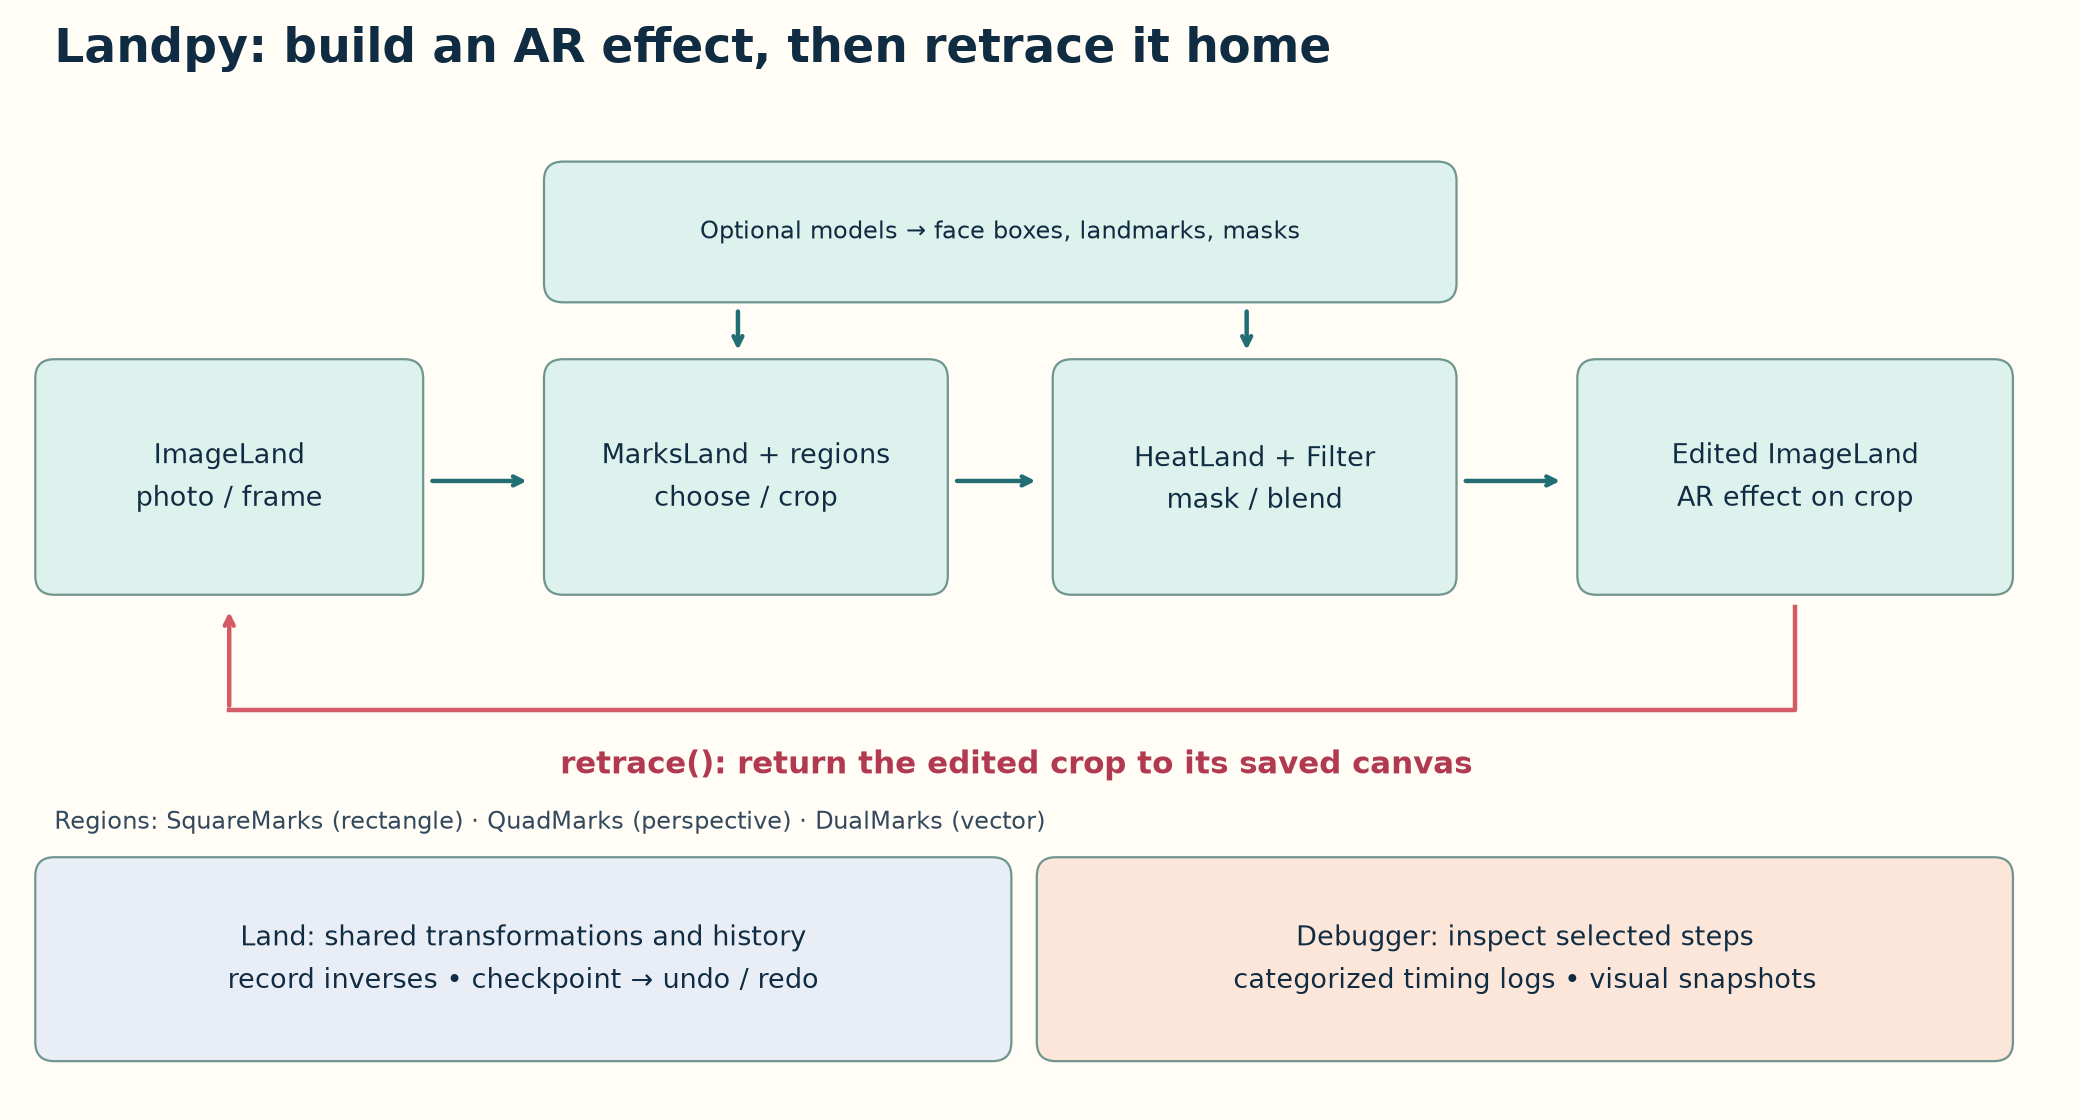

[Open the project map at full size](https://github.com/bateni1380/landpy/blob/master/tutorials/assets/project-map.png).

Read the main path from left to right. **Images** hold pixels, **landmarks** describe locations, and **heat maps** control blend strength. The optional face models suggest locations and masks; they do not do the final effect for you. `Land` supplies shared history behavior, while `Debugger` makes selected steps visible.

You will learn these pieces as the effect needs them: **1** first edit → **2** placement → **3** masks → **4** retrace and undo → **5** perspective → **6** overlays → **7** model adapters → **8** complete face effect.

## Goal

Build a tiny AR-style color effect and learn the one loop behind Landpy: **crop → edit → retrace**. By the end, you can place an edit back on its original canvas and explain `(row, column)` coordinates.

## Setup

Run all cells from top to bottom in a fresh kernel. The setup cell installs Landpy 0.1.0 if needed. A CPU is enough. Python 3.10+ is supported; no model downloads are needed here.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.0'])
import numpy as np
from landpy import ImageLand, SquareMarks, Filter, Debugger


## Steps

### 1. Make an image

Image arrays are RGB (not OpenCV BGR). Floating-point input uses [0, 1]; integer input uses [0, 255]. Landpy owns a copy. Array access from `get_image()` is mutable.

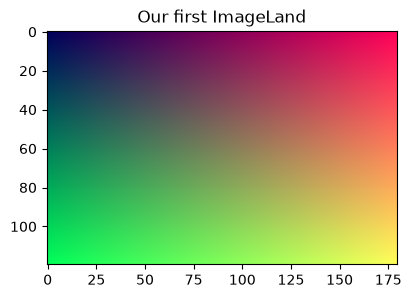

(120, 180) RGB uint8


In [2]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)

image.show('Our first ImageLand')
print(image.shape, image.mode, image.get_image().dtype)

### 2. Resize an independent copy

Shapes are `(height, width)`. Points are `(row, column)`. A `SquareMarks` rectangle uses row bounds named minX/maxX and column bounds named minY/maxY for compatibility with the original project.

Here the debugger gives us a labeled comparison without a plotting loop. The pictures occupy similar display space; the axis values reveal their different pixel dimensions.

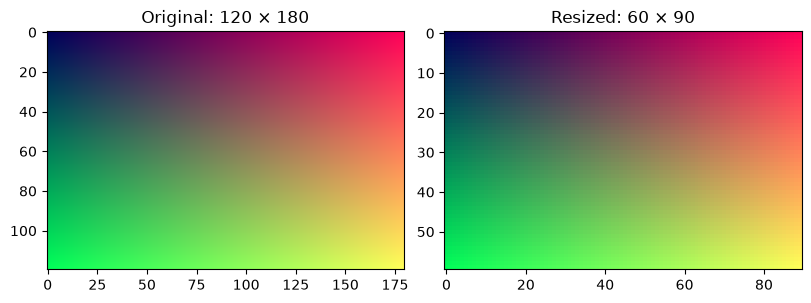

In [3]:
small = image.copy().reshape((60, 90))
debugger = Debugger(visual_debug=True)
debugger.log_images(
    [image.get_image(), small.get_image()],
    ['Original: 120 × 180', 'Resized: 60 × 90'],
    [Debugger.LogTypes.IMAGE] * 2,
);

### 3. Work with alpha and files

`to_rgba()` adds opaque alpha. `to_rgb()` composites onto black. File paths and Pillow images are accepted too; save a result with `PIL.Image.fromarray(image.get_image()).save(...)`.

In [4]:
rgba = image.copy().to_rgba()
print(rgba.mode, rgba.get_image()[0, 0])
help(ImageLand.reshape)

RGBA [  0   0  89 255]
Help on function reshape in module landpy.image_land:

reshape(self, shape, mode=None, save_trace=False)
    Resize to (height, width); retain mode unless RGB/RGBA is specified.



### 4. Your first crop → edit → retrace

Think of the rectangle as the place an AR sticker or tint will sit. We use a simple canvas first so you can see exactly which pixels change. `copy()` protects the original; methods usually change the object they are called on.

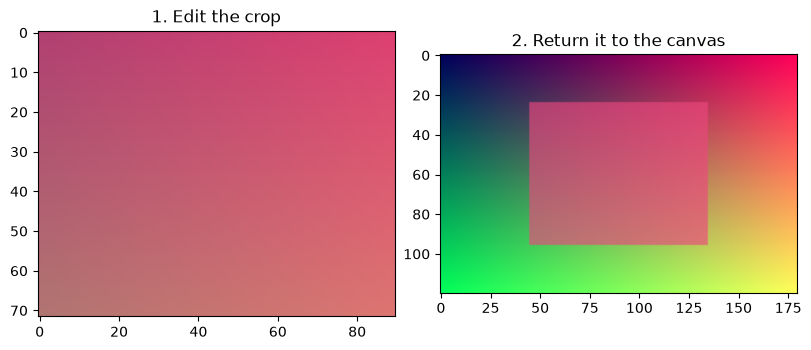

In [5]:
region = SquareMarks.relative(.2, .8, .25, .75, shape=image.shape)
effect = image.copy().zoom(region, save_trace=True)
effect.implant_filter(Filter('#ed477f', ratio=.65))
debugger.save_image(effect.get_image(), '1. Edit the crop')
effect.retrace()
debugger.save_image(effect.get_image(), '2. Return it to the canvas')
debugger.log_saved_images();
assert effect.shape == image.shape
np.testing.assert_array_equal(effect.get_image()[0, 0], image.get_image()[0, 0])

The pink region lands back in the center; the outer gradient is untouched. That is the core loop. Face landmarks will give us a more precise region later.

## Checks

In [6]:
assert image.shape == (120, 180)
assert small.shape == (60, 90)
assert rgba.get_image().dtype == np.uint8
assert np.all(rgba.get_image()[..., 3] == 255)
assert image.mode == 'RGB'

## Take it further 🚀

Now we can return an edit to its canvas. Next, learn to describe exactly **where** an effect belongs.

[Choose the next notebook](https://github.com/bateni1380/landpy/tree/master/tutorials)

**Try it:** Change the crop bounds and filter color. Does the edit return to the region you selected?

💬 This project began years ago. AI helped bring its original ideas to a finished package and tutorial journey—thank you, ChatGPT.

➡️ **[Continue to notebook 2](https://github.com/bateni1380/landpy/blob/master/tutorials/2-landmarks-and-regions.ipynb)**